In [199]:
import re, math
import pandas as pd
from collections import Counter
from sklearn.model_selection import train_test_split

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

train_df, val_df = train_test_split(train, test_size=0.2, stratify=train["author"], random_state=42)

def tokenize (text):
    tokens = re.findall(r'[a-z]+|\b\w+\b', text.lower())
    return tokens

In [200]:
#For each author, count how many times a word appears in their training sentences
count = {author: Counter() for author in train_df["author"].unique()}

for text, author in zip(train_df["text"], train_df["author"]):
    tokens = tokenize(text)
    count[author].update(tokens)

In [201]:
#Printing the count of each word according to the author
for author, c in count.items():
    print(author, c.most_common(10))

HPL [('the', 8767), ('and', 4830), ('of', 4667), ('a', 2641), ('to', 2579), ('i', 2198), ('in', 2186), ('was', 1706), ('that', 1617), ('had', 1443)]
MWS [('the', 7707), ('of', 4902), ('and', 4887), ('to', 3884), ('i', 3419), ('my', 2137), ('a', 2127), ('in', 2095), ('was', 1828), ('that', 1684)]
EAP [('the', 11881), ('of', 7117), ('and', 4593), ('to', 3805), ('a', 3754), ('in', 3257), ('i', 3020), ('it', 1888), ('that', 1794), ('was', 1775)]


In [202]:
doc_freq = Counter()
for text in train_df["text"]:
    tokens = set(tokenize(text))
    doc_freq.update(tokens)

#Words appearing in more than this fraction of sentences will be removed
#(trying to filter words that every author uses like "and", "to", "the", "of", etc; this was an attempt to remove noise and make the model more accurate)
#You can change the frequency_percentage variable to check for better values
frequency_percentage = 0.125
# I also made it so that the model also ignores a couple words if it appears only in a couple sentences, for example, if it appears only 5 times, then the model ignores it
# It so happens that not ignoring these words is actually the best option, so I set it to 0, and did not remove the code, because I think it is better to leave it documented
min_n_of_documents = 0
# This combination was the best I could find (0.125, 0), because it made the model as accurate as before the filter, and log loss decreased.

n_docs = len(train_df)
common = {p for p,  d in doc_freq.items() if d / n_docs > frequency_percentage}
#Also excluding words that are barely even used.
rare = {p for p, d in doc_freq.items() if d < min_n_of_documents}

#Filter that removes all tokens in common and rare
def filter_tokens(tokens):
    return [t for t in tokens if t not in common and t not in rare]

In [203]:
#Creating the counting array for the author, with only the words that leave the filter
filtered_count = {author: Counter() for author in train_df["author"].unique()}

for text, author in zip(train_df["text"], train_df["author"]):
    filtered_count[author].update(filter_tokens(tokenize(text)))

In [204]:
#Function that both tokenizes and filters.
#If remover_stop, filter and return the tokens, otherwise, just return the unfiltered tokens
def tokenize_and_filter(text, remover_stop=False):
    tokens = tokenize(text)
    return filter_tokens(tokens) if remover_stop else tokens

In [205]:
#Printing now the words that each author uses more frequently, with the filter on
for author, c in filtered_count.items():
    print(author, c.most_common(10))

HPL [('on', 741), ('were', 547), ('s', 512), ('they', 511), ('an', 505), ('me', 495), ('all', 450), ('be', 399), ('when', 396), ('or', 394)]
MWS [('her', 1338), ('me', 1152), ('you', 866), ('on', 823), ('she', 755), ('be', 633), ('were', 601), ('is', 553), ('have', 515), ('him', 514)]
EAP [('is', 1344), ('be', 869), ('have', 855), ('upon', 827), ('me', 733), ('all', 688), ('no', 682), ('so', 671), ('an', 663), ('or', 641)]


In [206]:
import math
from sklearn.metrics import accuracy_score, log_loss

#vocab = Getting the vocabulary, wich is the sum of all words an author used in the train
#totals = Getting the total of words each author has writen in the training set
#prior = Getting the fraction of sentences for each author
#Return everything in a form of dictionary.
def build_model(counts) :
    vocab = set()
    for c in counts.values():
        vocab.update(c)
    totals = {a: sum(c.values()) for a, c in counts.items()}
    prior = train_df["author"].value_counts(normalize=True).to_dict()
    return {"counts": counts, "vocab": vocab, "V": len(vocab), "totals": totals, "prior": prior}

#Breaks the sentence into tokens, and discards words that are not in the vocabulary 
#(also filters if filtered = True)
#Calculate the score for each author.
#Score function: (times_an_author_used_the_words + 1) / (total_of_words_of_the_author + size_of_vocab)
#Then turn the scores into probabilities
def predict_probabilities (model, text, filtered = False):
    tokens = filter_tokens(tokenize(text)) if filtered else tokenize(text)
    tokens = [t for t in tokens if t in model["vocab"]]

    scores = {}
    for author in model ["counts"]:
        s = math.log(model["prior"][author])
        for t in tokens:
            s += math.log((model["counts"][author][t] + 1) / (model["totals"][author] + model["V"]))
        scores[author] = s

    m = max(scores.values())
    exps = {a: math.exp(v - m) for a, v in scores.items()}
    z = sum(exps.values())
    probabilities = {a: e / z for a, e in exps.items()}
    return probabilities

In [207]:
model = build_model(count)
for i in range (20):
    row = val_df.iloc[i]
    print(row["text"])
    print("Real author:", row["author"])
    print(predict_probabilities(model, row["text"]))
    print("\n")

So blended bank and shadow there That each seemed pendulous in air so mirror like was the glassy water, that it was scarcely possible to say at what point upon the slope of the emerald turf its crystal dominion began.
Real author: EAP
{'HPL': 0.014013542658847074, 'MWS': 4.6902998552795836e-08, 'EAP': 0.9859864104381544}


I did only a retail business myself, but my old habits of system carried me swimmingly along.
Real author: EAP
{'HPL': 0.21605766319130673, 'MWS': 0.2779413975324704, 'EAP': 0.5060009392762229}


Old Waldron, who had curtailed his activities before, would have made him take a rest an impossible thing now that he was so close to great results in his equations.
Real author: HPL
{'HPL': 0.8461275960125185, 'MWS': 0.008484599656207644, 'EAP': 0.14538780433127382}


Let us refer, for example, to the last instance but one, in which the combination; occurs not far from the end of the cipher.
Real author: EAP
{'HPL': 0.0002035969414202539, 'MWS': 0.00010802219823708532, 'EAP

In [208]:
#Function that measures the accuracy of the model. It first gets the real author, and then gets the probabilities that the model gave for each author
#This function then picks the author with the greatest percentage in relation to the others as the model's definitive answer.
#Compares the real author with the predicted author and returns the accuracy.
#Then calculates the log loss
def evaluate (model, filtered) :
    classes = sorted(model["counts"])
    probabilities = [predict_probabilities(model, text, filtered) for text in val_df["text"]]
    y_pred = [max(p, key=p.get) for p in probabilities]
    acc = accuracy_score(val_df["author"], y_pred)
    ll = log_loss(val_df["author"], [[p[c] for c in classes] for p in probabilities], labels=classes)
    return acc, ll

In [209]:
#Printing the accuracy and log loss for both the filtered set, and the unfiltered
acc, ll = evaluate (build_model(count), filtered = False)
print (f"No filter: acc = {acc:.3f} log loss = {ll:.3f}")

acc, ll = evaluate (build_model(filtered_count), filtered = True)
print (f"Filtered:  acc = {acc:.3f} log loss = {ll:.3f}")

No filter: acc = 0.844 log loss = 0.480
Filtered:  acc = 0.844 log loss = 0.458


In [210]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Use our tokenizer, then remove the words we filtered out 
use_filter=True
def custom_tokenizer(text):
    return filter_tokens(tokenize(text)) if use_filter else tokenize(text)

# Turn the text into TF-IDF features for the model
vectorizer = TfidfVectorizer(
    tokenizer=custom_tokenizer,
    token_pattern=None,
    lowercase=False
)

# Learn the vocabulary from the training text and transform both sets
X_train = vectorizer.fit_transform(train_df["text"])
X_val = vectorizer.transform(val_df["text"])

y_train = train_df["author"]
y_val = val_df["author"]

# Train logistic regression on the training features and author labels
lr_model = LogisticRegression(max_iter=1000, )
lr_model.fit(X_train, y_train)

y_hat_f = lr_model.predict(X_val)

# The accuracy seems to be slightly worse than the original model but I figure it could be helpful in an ensemble
print("Validation accuracy:", accuracy_score(y_val, y_hat_f))
print(classification_report(y_val, y_hat_f))

Validation accuracy: 0.8260980592441267
              precision    recall  f1-score   support

         EAP       0.80      0.88      0.84      1580
         HPL       0.84      0.78      0.81      1127
         MWS       0.85      0.80      0.82      1209

    accuracy                           0.83      3916
   macro avg       0.83      0.82      0.82      3916
weighted avg       0.83      0.83      0.83      3916



In [211]:
import numpy as np

# grabs original model with filtered words
nb_model = build_model(filtered_count)
# swapping the model with an unfiltered count usually traded slightly improved accuracy for slightly increased log loss 
# nb_model = build_model(count)

classes = lr_model.classes_
lr_probs = lr_model.predict_proba(X_val)
 
# nb_prob_dicts = [predict_probabilities(nb_model, text, filtered=False) 
# grab probabilities from original model from validation set
nb_prob_dicts = [predict_probabilities(nb_model, text, filtered=True)
                 for text in val_df["text"]]

# put the probalities from orginal model in the same class order as the lr model
nb_probs = np.array([
    [probabilities[label] for label in classes]
    for probabilities in nb_prob_dicts
])

# try different wieghts for the ensemble model
best_acc = float('-inf')
for lr_weight in [0.0, 0.25, 0.5, 0.75, 1.0]:
    ensemble_probs = lr_weight * lr_probs + (1 - lr_weight) * nb_probs
    ensemble_predictions = classes[np.argmax(ensemble_probs, axis=1)]

    # find the best weight for accuracy, ignoring log loss 
    acc_score = accuracy_score(y_val, ensemble_predictions)
    if acc_score > best_acc:
        best_weight = lr_weight
        best_acc = acc_score

    print(
        f"LR weight={lr_weight:.2f}, "
        f"accuracy={acc_score:.3f}, "
        f"log loss={log_loss(y_val, ensemble_probs, labels=classes):.3f}"
    )

# print best weight and set the ensemble model to use that weight
print(f"{(best_weight):.3f}")
ensemble_probs = best_weight * lr_probs + (1 - best_weight) * nb_probs
ensemble_predictions = classes[np.argmax(ensemble_probs, axis=1)]


LR weight=0.00, accuracy=0.844, log loss=0.458
LR weight=0.25, accuracy=0.845, log loss=0.408
LR weight=0.50, accuracy=0.847, log loss=0.431
LR weight=0.75, accuracy=0.844, log loss=0.474
LR weight=1.00, accuracy=0.826, log loss=0.535
0.500


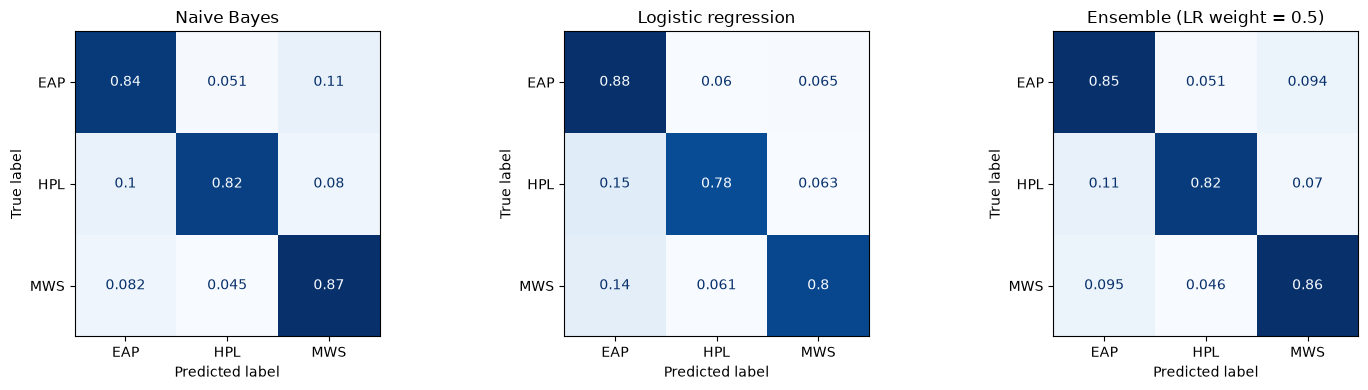

In [212]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

nb_predictions = classes[np.argmax(nb_probs, axis=1)]

#show the three confusion matrices side by side
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

#Bayes
ConfusionMatrixDisplay.from_predictions(y_val, nb_predictions, labels=classes, normalize='true', cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Naive Bayes")

#Logistic Regression
ConfusionMatrixDisplay.from_predictions(y_val, y_hat_f, labels=classes, normalize='true', cmap="Blues", ax=axes[1], colorbar=False)
axes[1].set_title("Logistic regression")

#Ensemble
ConfusionMatrixDisplay.from_predictions(y_val, ensemble_predictions, labels=classes, normalize='true', cmap="Blues", ax=axes[2], colorbar=False)
axes[2].set_title("Ensemble (LR weight = " + str(best_weight) + ")")

plt.tight_layout()
plt.savefig("confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()


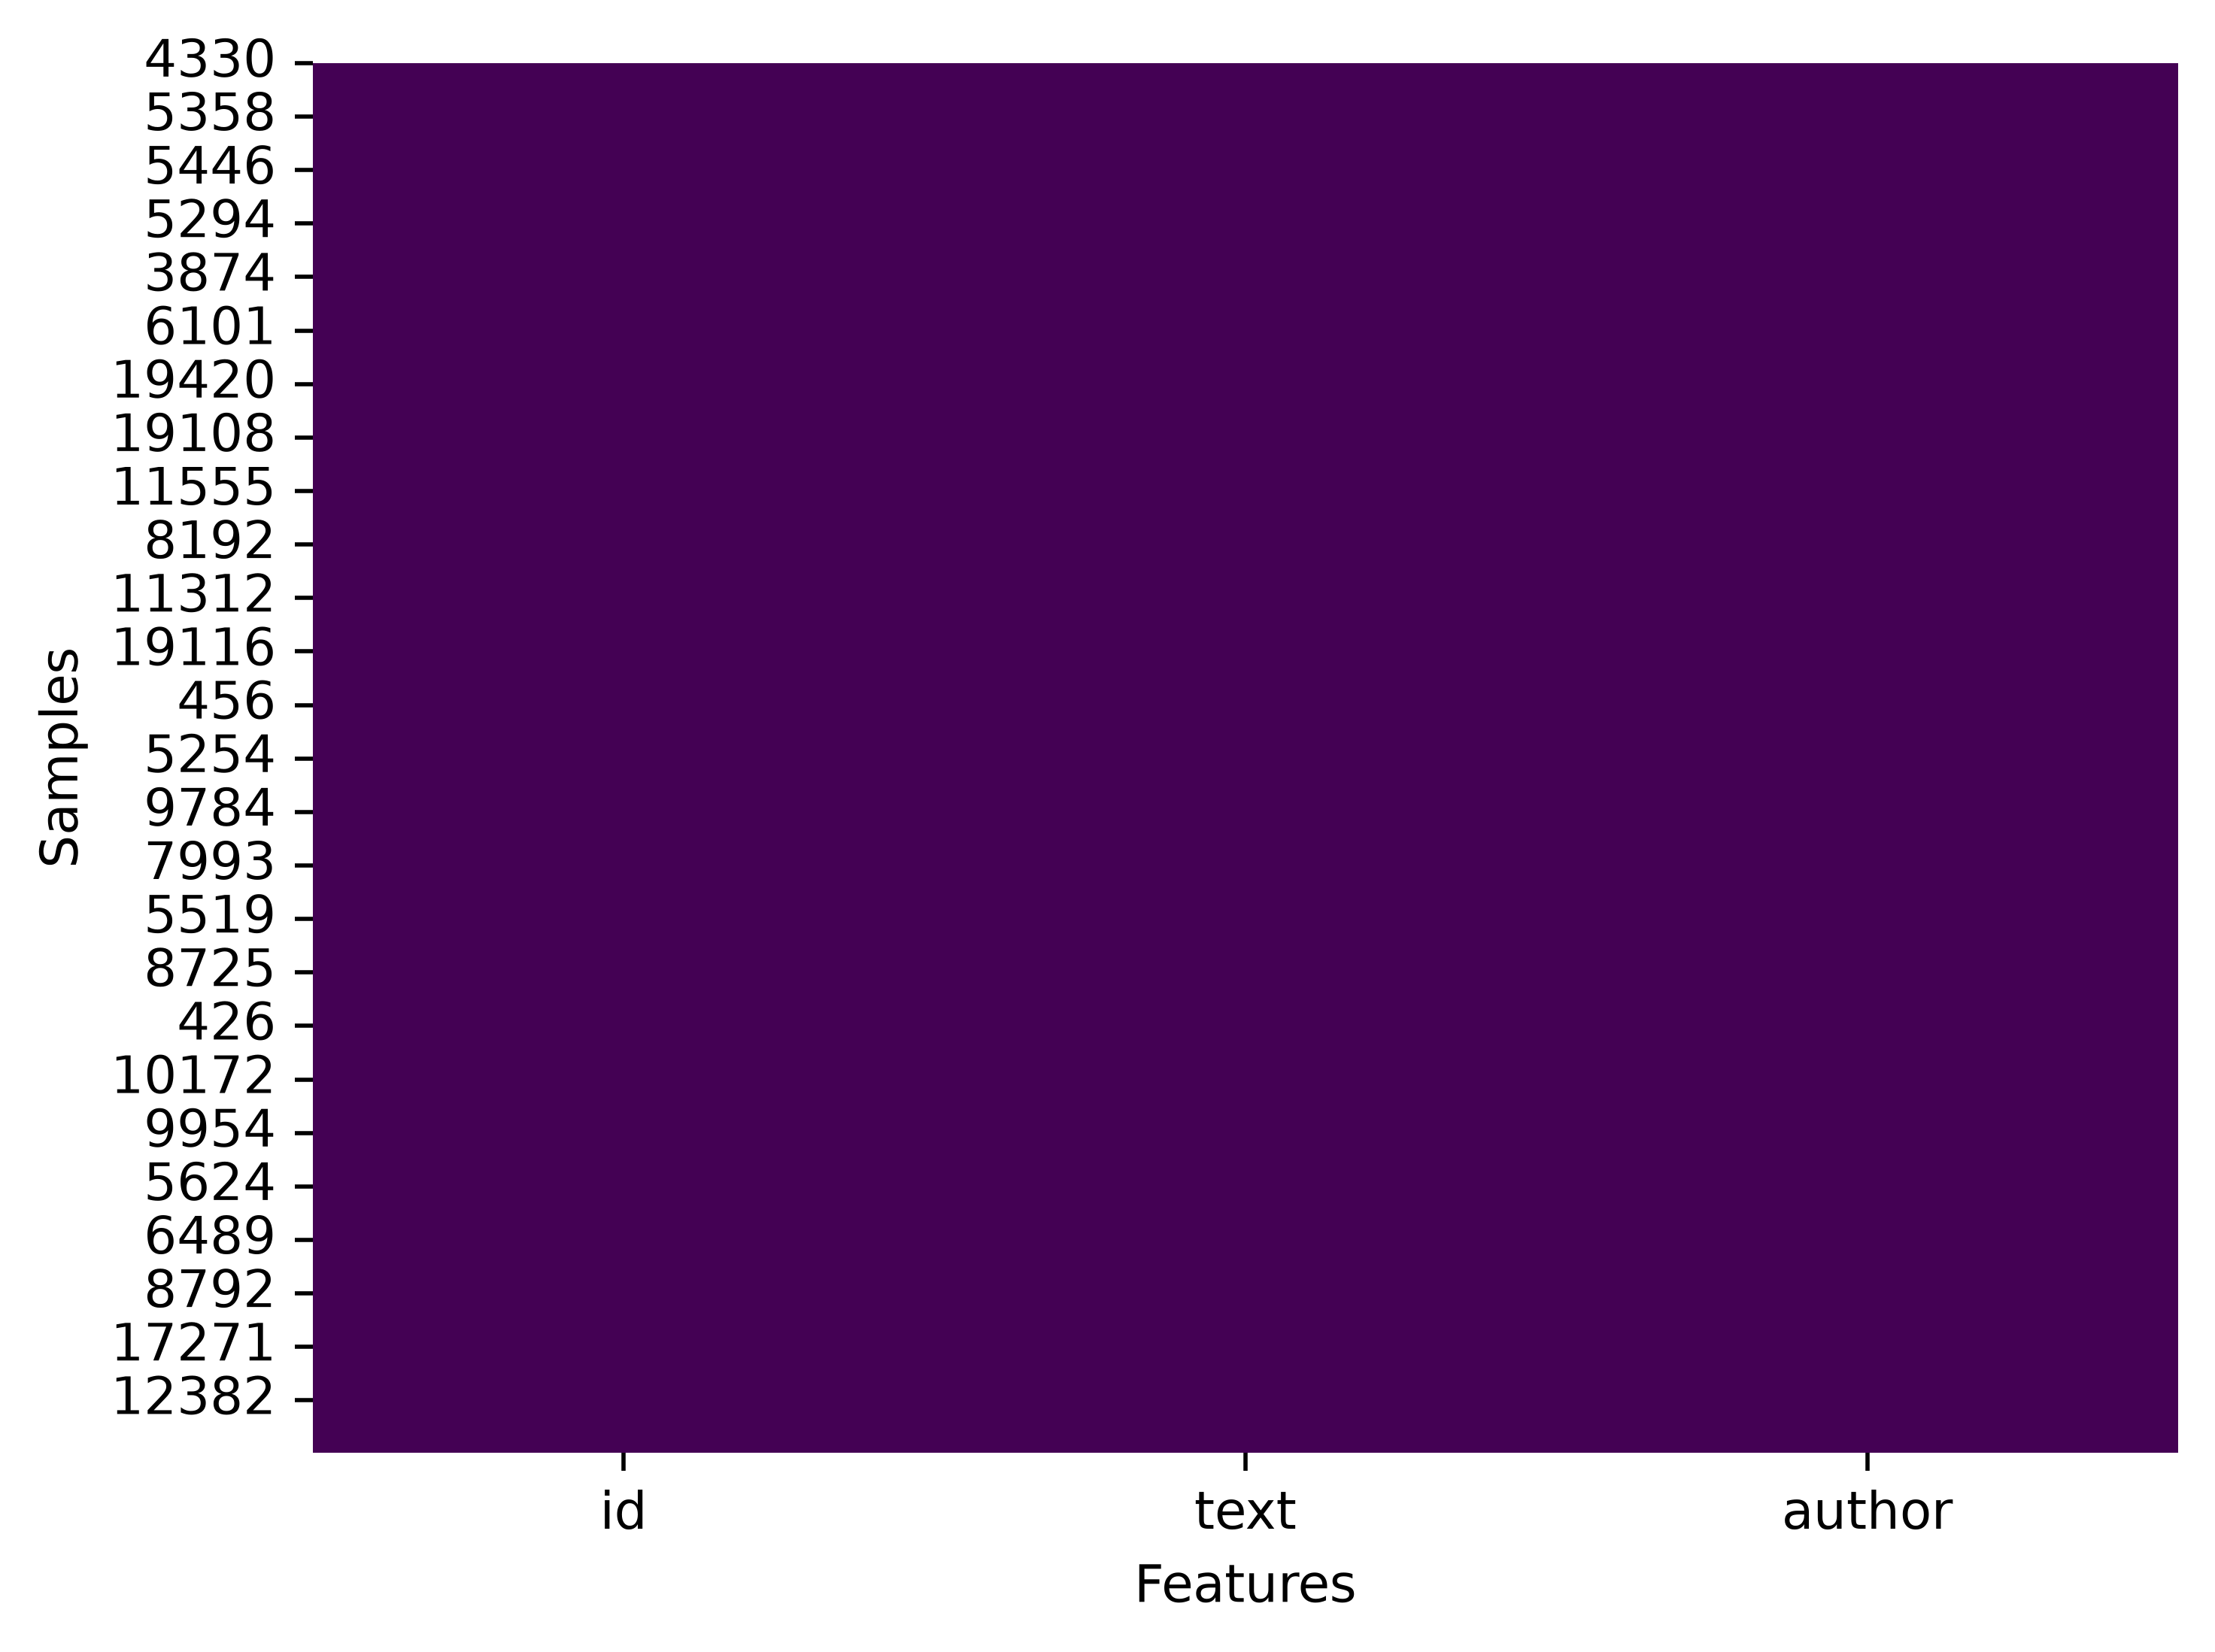

In [213]:
import seaborn as sns
plt.figure(dpi=500) # increase to ensure you can see each row
sns.heatmap(train_df.isnull() , cbar=False , cmap='viridis')
plt.ylabel('Samples')
plt.xlabel('Features')
plt.show()

In [214]:
# 1. Check for literal missing/NaN values (what your heatmap looks for)
print("--- NaN / Null Counts ---")
print(train_df.isnull().sum())

# 2. Check for empty strings or spaces hidden in the text column
print("\n--- Empty or Whitespace-Only Text Rows ---")
is_empty_text = train_df['text'].fillna('').str.strip() == ''
print(f"Number of blank text entries: {is_empty_text.sum()}")

# 3. Check for rows completely missing an author name/ID
is_empty_author = train_df['author'].fillna('').str.strip() == ''
print(f"Number of blank author entries: {is_empty_author.sum()}")

--- NaN / Null Counts ---
id        0
text      0
author    0
dtype: int64

--- Empty or Whitespace-Only Text Rows ---
Number of blank text entries: 0
Number of blank author entries: 0


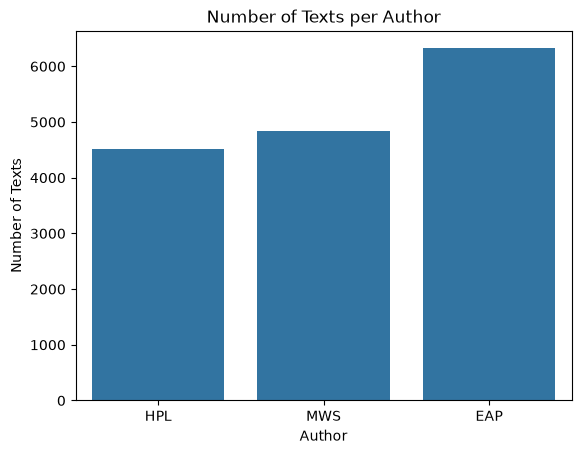

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Shows an imbalance distribution of texts per author
sns.countplot(data=train_df, x="author")
plt.title("Number of Texts per Author")
plt.xlabel("Author")
plt.ylabel("Number of Texts")
plt.show()